### [GALT] Vežba 2: Sintetička populacija zvezda

### <font color='yellow'>Ideja vežbe: Generisanje sintetičke populacije zvezda koristeći inicijalnu funkciju mass (initial mass function) i analiziranje Malmkvistove neobjektivnosti.</font>

#### <font color='red'>Na kraju svakog koraka, kada odradite ono što je bilo pitanje potrebno je iskomentarisati rešenje!</font>

#### Uvod


Statističko opisivanje zvezdanih populacija u astrofizici temelji se na dva ključna teorijska koncepta: raspodeli masa pri rođenju i rezultujućoj raspodeli luminoznosti.
1. Inicialna funkcija mase (_initial mass function_) definiše relativnu zastupljenost zvezda po jediničnom intervalu mase u trenutku njihovog formiranja. Prema empirijskom Salpeterovom zakonu (1955), ova raspodela prati funkciju stepenog zakona:
$$\frac{dN}{dM} \propto M^{-\alpha}, \quad \alpha \approx 2.35.$$
Ovaj odnos ukazuje na izrazitu dominaciju zvezda malih masa u poređenju sa masivnim objektima.
Naravno, postoji mnogo modernijih IMF, npr. Miller-Scalo IMF, Chabrier IMF, ali u ovoj vežbi, jednostavnosti radi, koristićemo prvu predloženu. (https://articles.adsabs.harvard.edu/pdf/1955ApJ...121..161S)

2. Dok IMF opisuje maseni spektar, funkcija luminoznosti (LF) kvantifikuje gustinu broja zvezda po jedinici zapremine u opsegu određenog sjaja ili magnitude. Prelaz sa mase na luminoznost ostvaruje se putem relacije masa-luminoznost ($L \propto M^{3.5}$ za zvezde glavnog niza), čime se teorijske mase prevode u posmatračke veličine — apsolutne magnitude. U posmatračkoj astrofizici, poznavanje funkcije luminoznosti je neophodno za modelovanje efekata selekcije i ispravnu rekonstrukciju prostorne distribucije zvezdanih sistema.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

##### <font color="green">1. Semplovati 10000 zvezda koje prate Salpeterovu IMF. Uzeti da je minimalna masa zvezde 0.08MSun, a maksimalna npr. 200MSun. (Hint: Učili ste na astrostatistici kako se to radi, inverse transform sampling.)</font>

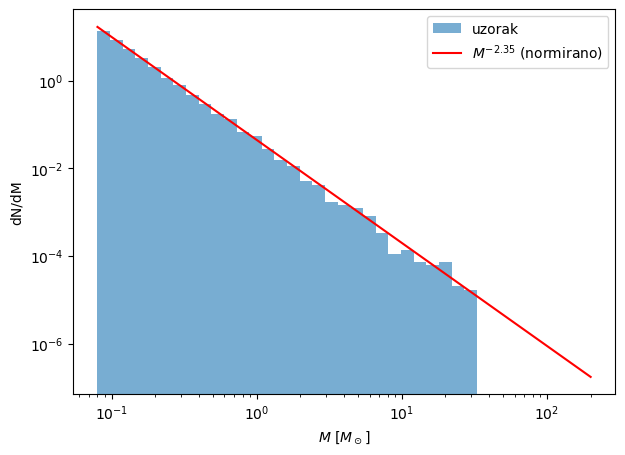

min = 0.080, max = 31.9, medijana = 0.132, udeo M<1 Msun: 97.01%


In [9]:
np.random.seed(42)
N = 10000                   # br zvezda
alpha = 2.35                # iz formule
Mmin, Mmax = 0.08, 200.0    # zadato

# Inverse transform sampling: CDF(M) = (M^(1-a) - Mmin^(1-a)) / (Mmax^(1-a) - Mmin^(1-a))
a1 = 1 - alpha                        # uvodim a1 da ne pisem svuda (1-alfa)
u = np.random.uniform(0, 1, N)        # uniformna raspodela
M = (Mmin**a1 + u * (Mmax**a1 - Mmin**a1))**(1 / a1)     # semplovane mase

# Provera: histogram u log-log skali + teorijska kriva
bins = np.logspace(np.log10(Mmin), np.log10(Mmax), 40)
plt.figure(figsize=(7, 5))
plt.hist(M, bins=bins, density=True, alpha=0.6, label='uzorak')
Mg = np.logspace(np.log10(Mmin), np.log10(Mmax), 200)
norm = a1 / (Mmax**a1 - Mmin**a1)
plt.plot(Mg, norm * Mg**(-alpha), 'r', label=r'$M^{-2.35}$ (normirano)')
plt.xscale('log'); plt.yscale('log')
plt.xlabel(r'$M\ [M_\odot]$'); plt.ylabel('dN/dM'); plt.legend()
plt.show()
print(f"min = {M.min():.3f}, max = {M.max():.1f}, medijana = {np.median(M):.3f}, udeo M<1 Msun: {np.mean(M<1):.2%}")

**Komentar:** Inverse transform sampling daje uzorak koji se dobro poklapa sa teorijskom krivom $M^{-2.35}$ u log-log skali (prava linija nagiba $-2.35$). Dominiraju zvezde malih masa (oko 97% uzorka ima $M<1\,M_\odot$), dok su masivne zvezde vrlo retke: najmasivnija u uzorku ima oko $30\,M_\odot$, iako je gornja granica $200\,M_\odot$ (verovatnoća da se takva zvezda uopšte pojavi u $10^4$ uzoraka je mala). 

##### <font color="green">2. Odrediti luminoznost i apsolutnu magnitudu svih zvezda.</font>

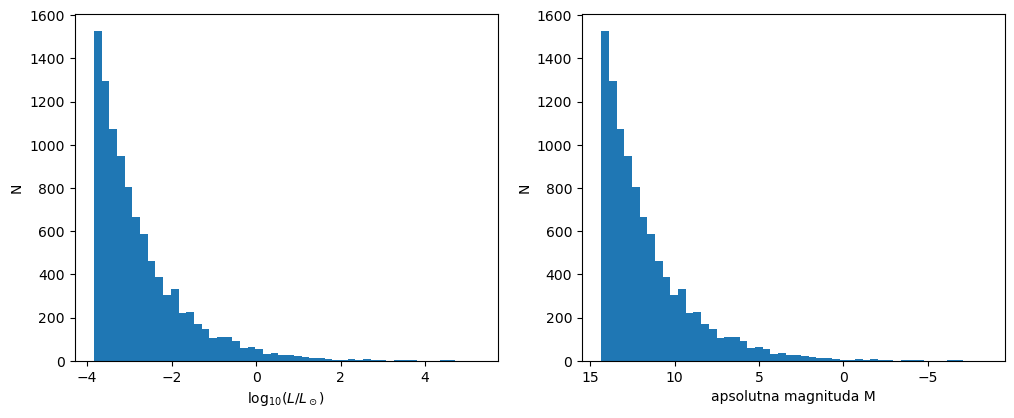

M_abs: od -8.4 (najsjajnija) do 14.3 (najslabija)


In [3]:
M_sun_abs = 4.74   # bolometrijska apsolutna magnituda Sunca

L = M**3.5                                   # L/Lsun (relacija masa-luminoznost)
Mabs = M_sun_abs - 2.5 * np.log10(L)         # apsolutna magnituda

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].hist(np.log10(L), bins=50)
ax[0].set_xlabel(r'$\log_{10}(L/L_\odot)$'); ax[0].set_ylabel('N')
ax[1].hist(Mabs, bins=50)
ax[1].invert_xaxis()
ax[1].set_xlabel('apsolutna magnituda M'); ax[1].set_ylabel('N')
plt.show()
print(f"M_abs: od {Mabs.min():.1f} (najsjajnija) do {Mabs.max():.1f} (najslabija)")

**Komentar:** Pošto je $L\propto M^{3.5}$, raspon masa od oko 3 reda veličine prelazi u raspon luminoznosti od oko 9 redova veličine (a time i oko 20+ magnituda). Većina zvezda je slaba, a mali broj masivnih zvezda je ekstremno sjajan. 

##### <font color="green">3. Pretpostavljajući da je maksimalna udaljenost zvezda 10kpc, i da su uniformno raspoređene u sferi, semplovati njihove udaljenosti i odrediti prividne magnitude i prikazati histogram (m).</font>

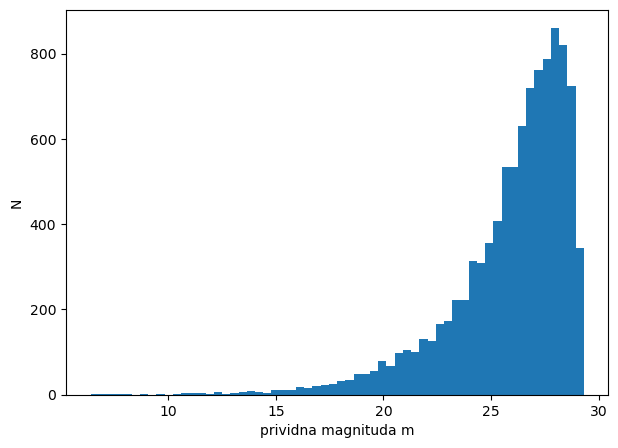

m: od 6.4 do 29.3, medijana = 26.6


In [4]:
Rmax = 10_000.0   # pc (10 kpc)

# Uniformno u sferi: P(<r) = (r/R)^3  ->  r = R * u^(1/3)
d = Rmax * np.random.uniform(0, 1, N)**(1/3)   # pc

# Modul rastojanja (d u pc)
m = Mabs + 5 * np.log10(d / 10)

plt.figure(figsize=(7, 5))
plt.hist(m, bins=60)
plt.xlabel('prividna magnituda m'); plt.ylabel('N')
plt.show()
print(f"m: od {m.min():.1f} do {m.max():.1f}, medijana = {np.median(m):.1f}")

**Komentar:** Zapreminski uniformna raspodela znači $N(<r)\propto r^3$, tj. većina zvezda je na velikim udaljenostima (zato koristimo $r=R\,u^{1/3}$, a ne $r=R\,u$, što bi pogrešno nagomilalo zvezde u centru). Histogram prividnih magnituda raste ka slabim magnitudama jer je većina zvezda i slaba i daleka, a sa leve strane ima dugačak rep retkih sjajnih/bliskih zvezda. Ovde se ne uzima u obzir ekstinkcija.

##### <font color="green">4. Analizirati kako se menja broj detektovanih zvezda u zavisnosti od udaljenosti za maksimalnu prividnu magnitudu koja može biti detektovana od 15, 18 i 22.</font>

m_lim = 15: detektovano 67 / 10000 (0.67%); najdalja detektovana zvezda: 9.97 kpc
m_lim = 18: detektovano 211 / 10000 (2.11%); najdalja detektovana zvezda: 9.98 kpc
m_lim = 22: detektovano 977 / 10000 (9.77%); najdalja detektovana zvezda: 9.99 kpc


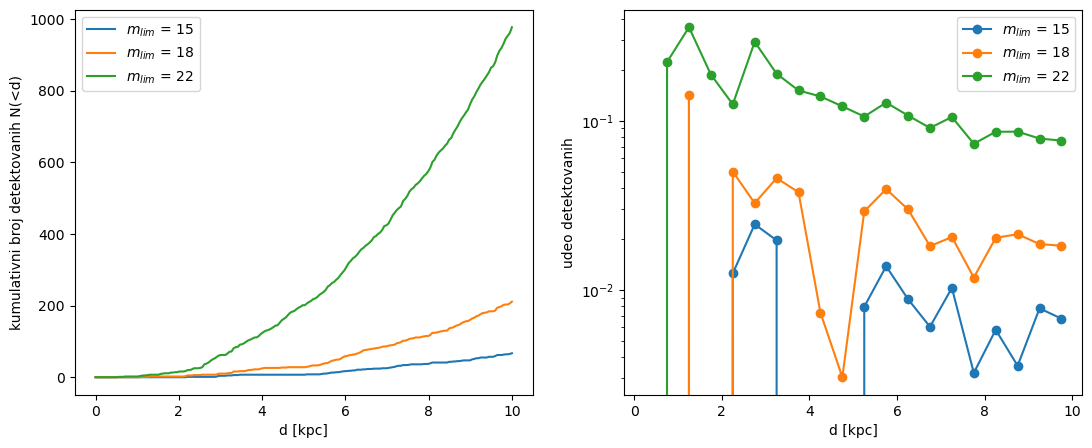

In [5]:
m_lims = [15, 18, 22]
d_grid = np.linspace(0, Rmax, 200)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
bins_d = np.linspace(0, Rmax, 21)
for ml in m_lims:
    det = m <= ml
    # kumulativni broj detektovanih zvezda do udaljenosti d
    N_cum = np.array([np.sum(det & (d <= dd)) for dd in d_grid])
    ax[0].plot(d_grid/1000, N_cum, label=f'$m_{{lim}}$ = {ml}')
    # udeo detektovanih po intervalima udaljenosti
    n_all, _ = np.histogram(d, bins=bins_d)
    n_det, _ = np.histogram(d[det], bins=bins_d)
    ax[1].plot(0.5*(bins_d[1:]+bins_d[:-1])/1000, n_det/np.maximum(n_all,1), 'o-', label=f'$m_{{lim}}$ = {ml}')
    print(f"m_lim = {ml}: detektovano {det.sum()} / {N} ({det.mean():.2%}); najdalja detektovana zvezda: {d[det].max()/1000:.2f} kpc")
ax[0].set_xlabel('d [kpc]'); ax[0].set_ylabel('kumulativni broj detektovanih N(<d)'); ax[0].legend()
ax[1].set_xlabel('d [kpc]'); ax[1].set_ylabel('udeo detektovanih'); ax[1].set_yscale('log'); ax[1].legend()
plt.show()

**Komentar:** Sa porastom granične magnitude raste i broj detektovanih zvezda, i detekcija seže do većih udaljenosti. Za $m_{lim}=15$ detektuje se samo oko 0.7% uzorka (67 zvezda), i to praktično samo vrlo luminozne (masivne) zvezde, jer su bliske zvezde retke zbog male zapremine; udeo detektovanih opada brzo sa udaljenošću. Najdalja detektovana zvezda je kod sve tri granice na skoro 10 kpc, ali je to uvek izuzetno sjajna zvezda. Za $m_{lim}=18$ je detektovano oko 2%, a za $m_{lim}=22$ oko 10% uzorka, ali i tada su najslabije zvezde (male mase) vidljive samo na malim udaljenostima. Kumulativni broj prvo raste kao $d^3$ (kada su svi detektovani), a zatim se uravnotežuje kada počne da deluje granica detekcije.

##### <font color="green">5. Prikazati grafike zavisnosti apsolutne magnitude od udaljenosti i označiti različitim simbolima detektovane i nedektovane zvezde, za sve tri granične magnitude. (Malmkvistova neobjektivnost)</font>

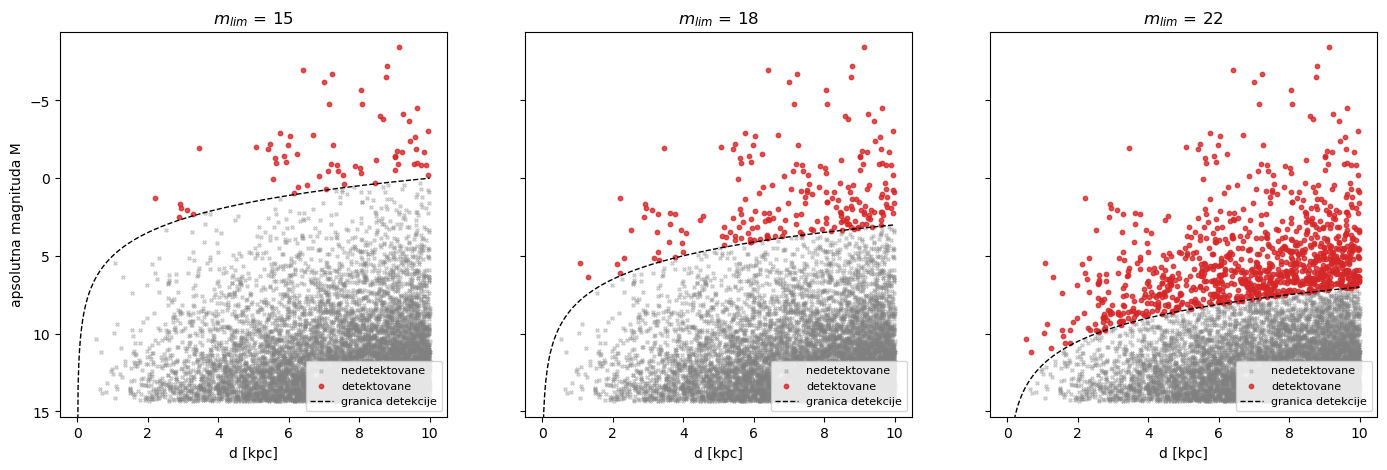

m_lim = 15: srednja M detektovanih u d<1 kpc: nan, u d>5 kpc: -2.13
m_lim = 18: srednja M detektovanih u d<1 kpc: nan, u d>5 kpc: 0.92
m_lim = 22: srednja M detektovanih u d<1 kpc: 10.73, u d>5 kpc: 4.81


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
for ax, ml in zip(axes, m_lims):
    det = m <= ml
    ax.scatter(d[~det]/1000, Mabs[~det], s=6, marker='x', c='gray', alpha=0.4, label='nedetektovane')
    ax.scatter(d[det]/1000, Mabs[det], s=10, marker='o', c='tab:red', alpha=0.8, label='detektovane')
    # granica detekcije: M = m_lim - 5 log10(d/10)
    dd = np.linspace(1, Rmax, 500)
    ax.plot(dd/1000, ml - 5*np.log10(dd/10), 'k--', lw=1, label='granica detekcije')
    ax.set_title(f'$m_{{lim}}$ = {ml}')
    ax.set_xlabel('d [kpc]')
    ax.set_ylim(Mabs.max()+1, Mabs.min()-1)
    ax.legend(loc='lower right', fontsize=8)
axes[0].set_ylabel('apsolutna magnituda M')
plt.show()

for ml in m_lims:
    det = m <= ml
    print(f"m_lim = {ml}: srednja M detektovanih u d<1 kpc: {Mabs[det & (d<1000)].mean() if np.any(det & (d<1000)) else float('nan'):.2f}, u d>5 kpc: "
          f"{Mabs[det & (d>5000)].mean():.2f}")

**Komentar (Malmkvistova neobjektivnost):** Granica detekcije je kriva $M=m_{lim}-5\log_{10}(d/10)$, i sa udaljenošću se pomera ka sve sjajnijim apsolutnim magnitudama. Zato je na većim udaljenostima uzorak detektovanih zvezda sve više sastavljen od intrinzički sjajnih zvezda, pa je njihova srednja apsolutna magnituda sistematski sjajnija od prave srednje vrednosti populacije. Ako bismo funkciju luminoznosti procenjivali iz uzorka ograničenog prividnom magnitudom bez korekcije, dobili bismo pristrasnu (preoptimističnu) sliku. Ovaj efekat je slabiji za dublje posmatranje ($m_{lim}=22$) jer je tada tačka preseka granice i populacije pomerena na veće udaljenosti. Rešenje je da se koristi uzorak ograničen zapreminom (npr. samo $d<d_{lim}$ u kome su sve zvezde date luminoznosti kompletne) ili da se primeni korekcija ($V/V_{max}$).